In [1]:
import os
import numpy as np
from spicelib import RawRead
from scipy import integrate
import matplotlib.pyplot as plt

fpath = '../mydesign/inverter/schematic/simulation'
fname = 'inverter_measure.raw'
raw = RawRead(os.path.join(fpath, fname))

['v(v-sweep)', 'v(vout)', 'v(vin)', 'v(vdd)', 'i(v2)', 'i(v1)']
Consumed Energy : 7.258e-04 (J)


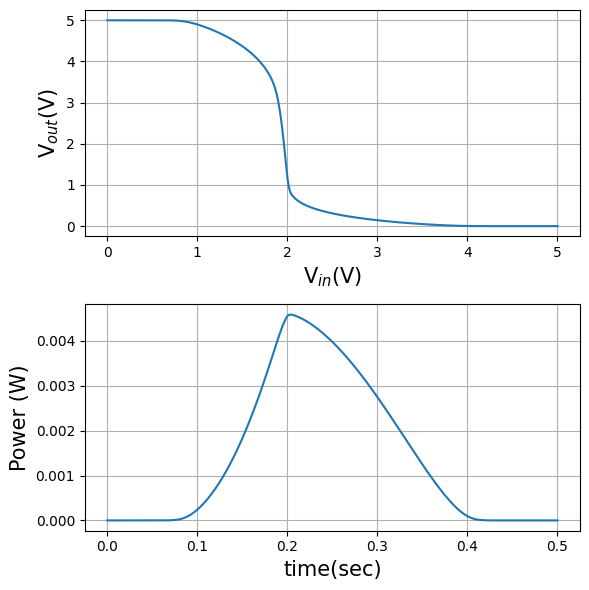

OrderedDict({'Filename': '../mydesign/inverter/schematic/simulation/inverter_measure.raw', 'Title': '** sch_path: /home/mychip/mydesign/inverter/schematic/inverter_measure.sch', 'Date': 'Mon May 11 22:09:12  2026', 'Command': 'ngspice-45.2, Build Wed Dec 17 14:59:05 UTC 2025', 'Plotname': 'DC transfer characteristic', 'Flags': 'real', 'No. Variables': '6', 'No. Points': '501', 'Variables': ['v(v-sweep)', 'v(vout)', 'v(vin)', 'v(vdd)', 'i(v2)', 'i(v1)']})


In [2]:
print(raw.get_trace_names())
vin = np.array(raw.get_trace('v(vin)'))
vout = np.array(raw.get_trace('v(vout)'))
iin = np.array(raw.get_trace('i(v2)'))
pin = - vin * iin

time_step = 0.001
time = np.array([time_step * i for i in range(len(vin))])
I = integrate.simpson(pin, x=time)
print('Consumed Energy : %.3e (J)' % I)

fig = plt.figure(figsize=(6,6))
ax1 = fig.add_subplot(211)
ax1.plot(vin, vout)
ax1.set_xlabel('V$_{in}$(V)', fontsize=15)
ax1.set_ylabel('V$_{out}$(V)',fontsize=15)
ax1.grid(True)

ax2 = fig.add_subplot(212)
ax2.plot(time, pin)
ax2.set_xlabel('time(sec)', fontsize=15)
ax2.set_ylabel('Power (W)',fontsize=15)
ax2.grid(True)

plt.tight_layout()
plt.show()

print(raw.get_raw_properties())